# SHOTpy Tutorial - Advanced Usage and Extensions

This notebook demonstrates how SHOT can be used in a Python ecosystem. The problem and modelling are based on **[1, 2]** and parts of the code have been generated with AI.


**[1]** Harjunkoski, I., Pörn, R., & Westerlund, T. (2025). MINLP: Trim-Loss Problem. In P. M. Pardalos, & O. A. Prokopyev (Eds.), Encyclopedia of Optimization (pp. 1-10). Springer, Cham. https://doi.org/10.1007/978-3-030-54621-2_387-1


**[2]** I. Harjunkoski, R. Pörn, T. Westerlund, H. Skrifvars. Different strategies for solving bilinear integer non-linear programming problems with convex transformations,
Computers & Chemical Engineering, Volume 21, Supplement, 1997, Pages S487-S492. https://doi.org/10.1016/S0098-1354(97)87549-7.

## SHOT in Python Ecosystem: Trim-Loss Problem

In paper production, large jumbo rolls are cut into smaller rolls of specified widths using predefined cutting patterns. Because customer orders differ in both width and quantity, not all material can be fully utilized. The remaining unusable material, known as trim loss, is typically recycled or reprocessed, which incurs additional operational costs and increases energy, water, and chemical consumption. Therefore, minimizing trim loss is a key objective in reducing both production cost and environmental impact.

**Sets**
- $I$: Set of product (roll width) types, indexed by $i$
- $J$: Set of cutting patterns, indexed by $j$

**Parameters**
- $w_i$: Width of product $i \in I$
- $W_{j,\max}$: Width of raw paper (jumbo reel) used in cutting pattern $j \in J$
- $T_j$: Maximum allowable trim-loss width for pattern $j \in J$
- $N_{j,\max}$: Maximum number of products that can be cut in pattern $j \in J$
- $M_j$: Upper bound on the number of times pattern $j \in J$ is repeated
- $n_{i,\text{order}}$: Ordered quantity (demand) of product $i \in I$
- $c_j$: Cost coefficient for the number of repetitions of pattern $j \in J$
- $C_j$: Cost coefficient for the activation of pattern $j \in J$

**Variables**
- $n_{ij} \in \mathbb{Z}_{\ge 0}$: Number of times product $i \in I$ appears in cutting pattern $j \in J$
- $m_j \in \mathbb{Z}_{\ge 0}$: Number of times cutting pattern $j \in J$ is repeated
- $y_j \in \{0,1\}$: Binary variable equal to $1$ if cutting pattern $j \in J$ is used, $0$ otherwise

**Model**
\begin{align}
\min_{m_j, n_{ij}, y_j} \quad & \sum_{j=1}^{J} \left( c_j \cdot m_j + C_j \cdot y_j \right) 
    && \text{(minimize total patterns and pattern changes)} \\[6pt]
\text{s.t.} \quad
& \sum_{i=1}^{I} w_i \cdot n_{ij} \leq W_{j,\max} 
    && \text{(cuts must not exceed raw paper width)} \\
&  W_{j,\max} - T_j \leq \sum_{i=1}^{I} w_i \cdot n_{ij}
    && \text{(trim loss must not exceed maximum allowable width)} \\
& \sum_{i=1}^{I} n_{ij} \leq N_{j,\max} 
    && \text{(number of cuts per pattern bounded by } N_{j,\max}\text{)} \\
& y_j \leq  m_j
    && \text{(pattern } j \text{ must be active if used)} \\
& m_j \leq  M_j \cdot y_j, \qquad j = 1, \ldots, J 
    && \text{(pattern repetitions bounded by } M_j \text{ if active)} \\
& n_{i,\text{order}}\leq \sum_{j=1}^{J} m_j \cdot n_{ij}, \qquad i = 1, \ldots, I 
    && \text{(bilinear demand constraint: customer order must be met)} \\
& m_j,\, n_{ij} \in \mathbb{Z}, \quad y_j \in \{0, 1\} 
    && \text{(integrality and binary requirements)}
\end{align}


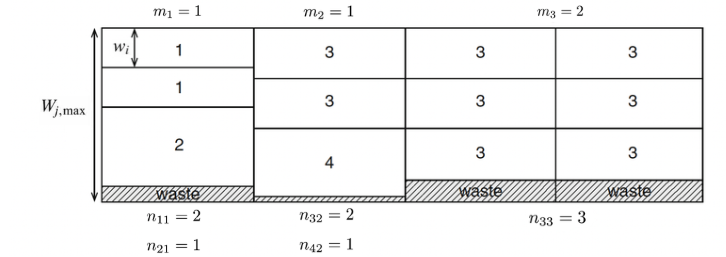

**Figure 1:** Trimm-Loss Problem **[1]**. 


In this tutorial, we solve an instance with 5 products and 6 cutting patterns, which is loaded from the CSV files `products.csv` and `patterns.csv` in Step 1.

Also note that the Trim-Loss problem is a nonconvex MINLP problem, since the demand constraint is bilinear. However, it can be written as a convex MINLP formulation (see **[2]**). As the focus of this tutorial is to demonstrate how SHOT can be used in a Python ecosystem, we use that convex formulation in Step 2 without going into its details.

### Setup
First, install SHOTpy and the Python libraries used in this notebook, then import them.

In [1]:
%pip install SHOTpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math

import SHOTpy

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

### Step 1: Loading Problem Data
Let's start with loading the problem data from the CSV-files.

In [3]:
# Products: width w_i and ordered quantity n_i,order
products_df = pd.read_csv("products.csv")
display(HTML(products_df.to_html(index=False)))

products = products_df["product"].tolist()
widths = products_df["w_i"].tolist()
orders = products_df["order"].tolist()

# Cutting patterns: W_j,max, T_j, N_j,max, M_j, c_j and C_j
patterns_df = pd.read_csv("patterns.csv")
display(HTML(patterns_df.to_html(index=False)))

patterns = patterns_df["pattern"].tolist()
W_max = patterns_df["W_max"].tolist()
T = patterns_df["T_j"].tolist()
N_max = patterns_df["N_max"].tolist()
M = patterns_df["M_j"].tolist()
cost_rep = patterns_df["c_j"].tolist()   # c_j: cost per repetition of pattern j
cost_act = patterns_df["C_j"].tolist()   # C_j: cost of activating pattern j

# Sets
I = list(range(len(products)))   # products
J = list(range(len(patterns)))   # patterns

product,w_i,order
Pr1,3,10
Pr2,5,6
Pr3,4,12
Pr4,6,8
Pr5,4,12


pattern,W_max,T_j,N_max,M_j,c_j,C_j
Pa1,20,2,4,10,2,5
Pa2,20,2,4,10,1,3
Pa3,20,3,3,12,3,4
Pa4,20,4,3,11,1,4
Pa5,20,3,3,8,4,4
Pa6,20,4,3,9,5,4


### Step 2: Build and Solve the Trim-Loss Model

Since the extension at the end of this notebook solves the same model again, the model is built by a function, `build_trimloss_model(solver)`, which returns the finalized problem and its variables $n_{ij}$, $m_j$ and $y_j$. The numbers in the comments refer to the equations of the model above.

In [4]:
def build_trimloss_model(solver):
    """Create the trim-loss problem; returns the finalized problem and the variables n, m and y."""
    problem = SHOTpy.Problem(solver)
    Integer, Binary = SHOTpy.VariableType.Integer, SHOTpy.VariableType.Binary

    # Variables
    n = {(i, j): problem.addVariable(f"n_{i+1}_{j+1}", Integer, 0) for i in I for j in J}   # product i in pattern j
    m, y = {}, {}
    for j in J:
        m[j] = problem.addVariable(f"m_{j+1}", Integer, 0, M[j])   # repetitions of pattern j
        y[j] = problem.addVariable(f"y_{j+1}", Binary)             # pattern j is used

    # (1) Objective: cost of the pattern repetitions and of the pattern changes
    problem.setObjective(sum(cost_rep[j] * m[j] + cost_act[j] * y[j] for j in J), SHOTpy.ObjectiveDirection.Minimize)

    # (2)+(3) Width bounds per pattern: W_max[j] - T[j] <= sum_i w_i * n_ij <= W_max[j]
    for j in J:
        problem.addConstraint(SHOTpy.inequality(W_max[j] - T[j], sum(widths[i] * n[i, j] for i in I), W_max[j]),
                              f"width_{j+1}")

    # (4) Max cuts per pattern: sum_i n_ij <= N_max[j]
    for j in J:
        problem.addConstraint(sum(n[i, j] for i in I) <= N_max[j], f"max_cuts_{j+1}")

    # (5) Pattern must be active if used: y_j <= m_j
    for j in J:
        problem.addConstraint(y[j] <= m[j], f"active_if_used_{j+1}")

    # (6) Repetitions bounded when active: m_j <= M_j * y_j
    for j in J:
        problem.addConstraint(m[j] <= M[j] * y[j], f"bounded_if_active_{j+1}")

    # (7) Demand: sum_j m_j * n_ij >= n_i,order is bilinear and thus nonconvex, so we use the convex
    #     formulation of [2] (technical details, not the focus of this tutorial).
    #     m_j and r_ij = N_max[j] - n_ij are encoded with binary variables, of which at most one per group is 1:
    #       bm[j, l] = 1     <=>  m_j = l,   l = 1, ..., M_j
    #       bn[i, j, k] = 1  <=>  r_ij = k,  k = 1, ..., N_max[j]
    #     If all are 0, m_j = 0 or r_ij = 0 (i.e., n_ij = N_max[j])
    bm = {(j, l): problem.addVariable(f"bm_{j+1}_{l}", Binary) for j in J for l in range(1, M[j] + 1)}
    bn = {(i, j, k): problem.addVariable(f"bn_{i+1}_{j+1}_{k}", Binary)
          for i in I for j in J for k in range(1, N_max[j] + 1)}

    # (7a) Definition of m_j: m_j = sum_l l * bm[j, l]
    for j in J:
        problem.addConstraint(m[j] == sum(l * bm[j, l] for l in range(1, M[j] + 1)), f"mj_def_{j+1}")

    # (7b) Definition of n_ij via r_ij = N_max[j] - n_ij: n_ij + sum_k k * bn[i, j, k] = N_max[j]
    for i in I:
        for j in J:
            problem.addConstraint(n[i, j] + sum(k * bn[i, j, k] for k in range(1, N_max[j] + 1)) == N_max[j],
                                  f"nij_def_{i+1}_{j+1}")

    # (7c) At most one bm per pattern: sum_l bm[j, l] <= 1
    for j in J:
        problem.addConstraint(sum(bm[j, l] for l in range(1, M[j] + 1)) <= 1, f"sos1_bm_{j+1}")

    # (7d) At most one bn per product and pattern: sum_k bn[i, j, k] <= 1
    for i in I:
        for j in J:
            problem.addConstraint(sum(bn[i, j, k] for k in range(1, N_max[j] + 1)) <= 1, f"sos1_bn_{i+1}_{j+1}")

    # (7e) Convex demand constraint (τ = 1):
    #      sum_j [exp(Mj_log + Rij) - (N_max[j] + 1) * sum_l l * bm[j, l] - sum_k k * bn[i, j, k]] <= |J| - n_i,order
    #      where Mj_log = sum_l ln(l + 1) * bm[j, l] and Rij = sum_k ln(k + 1) * bn[i, j, k] are the
    #      log-space images of m_j and r_ij
    for i in I:
        demand = 0
        for j in J:
            Mj_log = sum(math.log(l + 1) * bm[j, l] for l in range(1, M[j] + 1))
            Rij = sum(math.log(k + 1) * bn[i, j, k] for k in range(1, N_max[j] + 1))
            demand += (SHOTpy.exp(Mj_log + Rij)
                       - (N_max[j] + 1) * sum(l * bm[j, l] for l in range(1, M[j] + 1))
                       - sum(k * bn[i, j, k] for k in range(1, N_max[j] + 1)))
        problem.addConstraint(demand <= len(J) - orders[i], f"demand_{i+1}")

    problem.finalize()
    return problem, n, m, y

In [5]:
# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Dual.MIP.Solver", int(SHOTpy.MIPSolver.Cbc))  # Gurobi, Cplex, Cbc or Highs

# Create problem
problem, n, m, y = build_trimloss_model(solver)

# Set problem
assert solver.setProblem(problem)

# Solve
assert solver.solveProblem()


 Performing bound tightening on original problem.
  - Bounds for 30 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [0, 178]

 Performing bound tightening on reformulated problem.
  - Bounds for 30 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [0, 178]

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

    Iteration     │  Time  │    Cuts     │     Objective value     │  Objective diff.   
     #: type      │  tot.  │   + | tot.  │    problem | line srch  │    abs. | rel.    
╶─────────────────┴────────┴─────────────┴─────────────────────────┴──────────────────╴
     1: LP           0.02                      -1e+12 | -1e+12          inf. | inf.    
     2: LP           0.02      8 | 8         -120.503 | 3.09624      1.2e+02 | 1.0e+00 
     3: LP           0.02      8 | 16        -40.6756 | 3.10247      4.4e+01 | 1.1e+0

In [6]:
# Print problem structure
print("Problem Structure:")
print(problem.toString())

# Check status
print(f"Status: {solver.getModelReturnStatus().name}")

# Get solution
sol = solver.getPrimalSolution()
print(f"Optimal objective value: {sol.objValue:.4f}")
print("Optimal solution (nonzero variables):")
for variable, value in zip(problem.allVariables, sol.point):
    if abs(value) > 1e-6:
        print(f"  {variable.name} = {value:.4f}")

Problem Structure:
minimize:
[L-convex    ] [L    ]	  +2*m_1 +5*y_1 +m_2 +3*y_2 +3*m_3 +4*y_3 +m_4 +4*y_4 +4*m_5 +4*y_5 +5*m_6 +4*y_6

subject to:
[    0,L-convex    ] [L    ]      width_1:18 <=   +3*n_1_1 +5*n_2_1 +4*n_3_1 +6*n_4_1 +4*n_5_1 <= 20
[    1,L-convex    ] [L    ]      width_2:18 <=   +3*n_1_2 +5*n_2_2 +4*n_3_2 +6*n_4_2 +4*n_5_2 <= 20
[    2,L-convex    ] [L    ]      width_3:17 <=   +3*n_1_3 +5*n_2_3 +4*n_3_3 +6*n_4_3 +4*n_5_3 <= 20
[    3,L-convex    ] [L    ]      width_4:16 <=   +3*n_1_4 +5*n_2_4 +4*n_3_4 +6*n_4_4 +4*n_5_4 <= 20
[    4,L-convex    ] [L    ]      width_5:17 <=   +3*n_1_5 +5*n_2_5 +4*n_3_5 +6*n_4_5 +4*n_5_5 <= 20
[    5,L-convex    ] [L    ]      width_6:16 <=   +3*n_1_6 +5*n_2_6 +4*n_3_6 +6*n_4_6 +4*n_5_6 <= 20
[    6,L-convex    ] [L    ]   max_cuts_1:  +n_1_1 +n_2_1 +n_3_1 +n_4_1 +n_5_1 <= 4
[    7,L-convex    ] [L    ]   max_cuts_2:  +n_1_2 +n_2_2 +n_3_2 +n_4_2 +n_5_2 <= 4
[    8,L-convex    ] [L    ]   max_cuts_3:  +n_1_3 +n_2_3 +n_3_3 +n_4_3 +n_5_3 

### Step 3: Visualize 
Alright, let's visualize the solution.

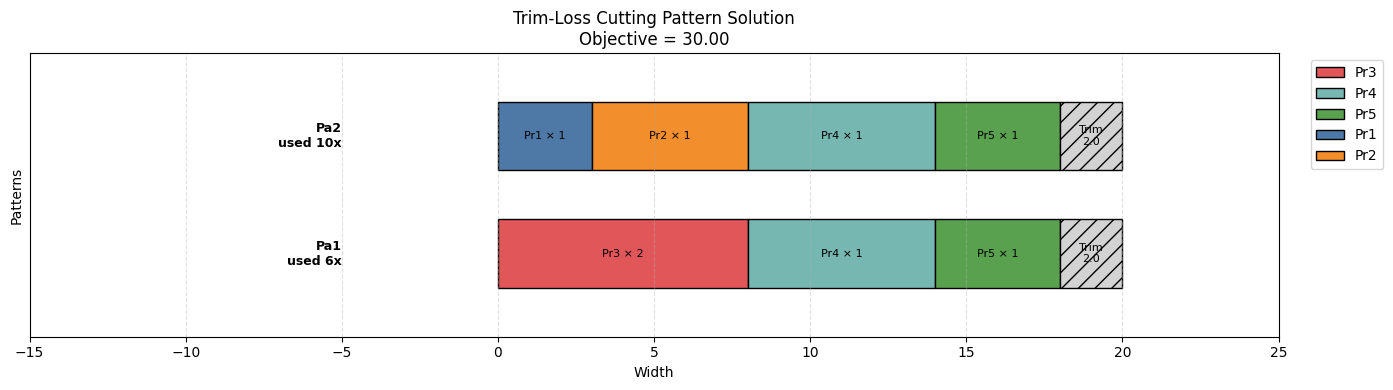

In [7]:
COLOR_PALETTE = [
    "#4E79A7", "#F28E2B", "#E15759", "#76B7B2",
    "#59A14F", "#EDC948", "#B07AA1", "#FF9DA7",
    "#9C755F", "#BAB0AC"
]
PRODUCT_COLORS = {products[i]: COLOR_PALETTE[i % len(COLOR_PALETTE)] for i in I}


def plot_patterns(point, n, m, title):
    """Draw each used cutting pattern as a bar of its cuts and its trim loss."""
    # Extract the used patterns from the solution point
    pattern_data = []

    for j in J:
        repetitions = round(point[m[j].index])
        if repetitions <= 0:
            continue   # ignore unused patterns

        cuts = [(products[i], round(point[n[i, j].index]), widths[i]) for i in I if round(point[n[i, j].index]) > 0]
        used_width = sum(count * width for _, count, width in cuts)
        pattern_data.append((patterns[j], repetitions, cuts, W_max[j] - used_width))

    # Plot
    fig, ax = plt.subplots(figsize=(14, max(4, len(pattern_data) * 1.2)))
    bar_height = 0.7
    legend_handles = {}

    for row, (pattern, repetitions, cuts, trim) in enumerate(pattern_data):
        y_pos = 1.2 * row
        x_start = 0

        # Cuts
        for product, count, width in cuts:
            ax.add_patch(patches.Rectangle((x_start, y_pos), count * width, bar_height,
                                           facecolor=PRODUCT_COLORS[product], edgecolor='black', linewidth=1))
            ax.text(x_start + count * width / 2, y_pos + bar_height / 2, f"{product} × {count}",
                    ha='center', va='center', fontsize=8)
            legend_handles.setdefault(product, patches.Patch(facecolor=PRODUCT_COLORS[product], edgecolor='black',
                                                             label=product))
            x_start += count * width

        # Trim loss
        if trim > 1e-6:
            ax.add_patch(patches.Rectangle((x_start, y_pos), trim, bar_height,
                                           facecolor='lightgray', edgecolor='black', hatch='//', linewidth=1))
            ax.text(x_start + trim / 2, y_pos + bar_height / 2, f"Trim\n{trim:.1f}", ha='center', va='center', fontsize=8)

        # Pattern label
        ax.text(-5, y_pos + bar_height / 2, f"{pattern}\nused {repetitions}x",
                ha='right', va='center', fontsize=9, fontweight='bold')

    # Formatting
    ax.set_xlim(-15, max(W_max) + 5)
    ax.set_ylim(-0.5, 1.2 * len(pattern_data))
    ax.set_xlabel("Width")
    ax.set_ylabel("Patterns")
    ax.set_title(title)
    ax.set_yticks([])
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.legend(handles=list(legend_handles.values()), loc='upper left', bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()


plot_patterns(sol.point, n, m, f"Trim-Loss Cutting Pattern Solution\nObjective = {sol.objValue:.2f}")

## Extension: Callback-Based Visualization

The previous section introduced SHOTpy when paired with some simple and useful Python libraries. Let's build on this and demonstrate how callbacks can be utilized in this context as well: we solve the same model again with `build_trimloss_model()`, and record every new primal solution with the `NewPrimalSolution` callback.

In [8]:
# Create solver
solver = SHOTpy.Solver()
solver.updateSetting("Dual.MIP.Solver", int(SHOTpy.MIPSolver.Cbc))  # Gurobi, Cplex, Cbc or Highs

# Disable continuous relaxation (solve as pure MIP) to get more solution points for demonstration purposes;
# in practice, enabling relaxation can speed up convergence
solver.updateSetting("Dual.Relaxation.Use", False)

# Create problem
problem, n, m, y = build_trimloss_model(solver)

# Set problem
assert solver.setProblem(problem)

# Register callback: track every new primal solution
primal_log = []

def on_new_primal(ctx):
    primal_log.append({
        "iter": ctx.iterationNumber,
        "sol": ctx.point,
        "obj": ctx.objectiveValue,
        "dual": ctx.dualBound,
        "gap (%)": 100 * ctx.relativeGap,
    })

solver.registerCallback(SHOTpy.CallbackLocation.NewPrimalSolution, on_new_primal)

# Solve
assert solver.solveProblem()


 Performing bound tightening on original problem.
  - Bounds for 30 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [0, 178]

 Performing bound tightening on reformulated problem.
  - Bounds for 30 variables tightened in 0.00 s and 2 passes.
  - Objective bounds are: [0, 178]

╶ Interior point search ──────────────────────────────────────────────────────────────────────────────────────────────╴

 Strategy selected:          cutting plane minimax

    Iteration     │  Time  │    Cuts     │     Objective value     │  Objective diff.   
     #: type      │  tot.  │   + | tot.  │    problem | line srch  │    abs. | rel.    
╶─────────────────┴────────┴─────────────┴─────────────────────────┴──────────────────╴
     1: LP           0.01                      -1e+12 | -1e+12          inf. | inf.    
     2: LP           0.01      8 | 8         -120.503 | 3.09624      1.2e+02 | 1.0e+00 
     3: LP           0.02      8 | 16        -40.6756 | 3.10247      4.4e+01 | 1.1e+0

In [9]:
print(f"Primal solution improvements ({len(primal_log)} updates):")
print(f"  {'iter':>5}  {'objective':>12}  {'dual bound':>12}  {'gap %':>8}")
for row in primal_log:
    print(f"  {row['iter']:>5}  {row['obj']:>12.6f}  {row['dual']:>12.6f}  {row['gap (%)']:>8.4f}")

Primal solution improvements (1 updates):
   iter     objective    dual bound     gap %
     12     30.000000      3.045192   89.8494


Great! Let's visualize both the convergence and the solutions at the different iterations.

In [10]:
# First add the final state of the solver
primal_log.append({
    "iter": solver.getSolutionStatistics().numberOfIterations,
    "sol": solver.getPrimalSolution().point,
    "obj": solver.getPrimalBound(),
    "dual": solver.getGlobalDualBound(),
    "gap (%)": 100 * solver.getRelativeObjectiveGap(),
})

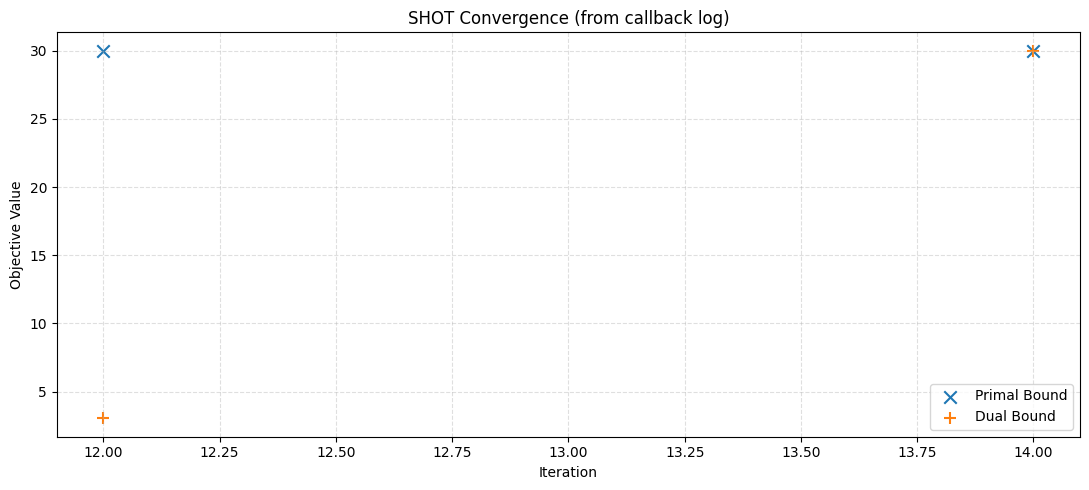

In [11]:
# Build DataFrame from callback log
df_conv = pd.DataFrame(primal_log).sort_values("iter", kind="stable")
dual_finite = df_conv[np.isfinite(df_conv["dual"])]

# Plot
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(df_conv["iter"], df_conv["obj"], s=80, marker='x', label="Primal Bound")
ax.scatter(dual_finite["iter"], dual_finite["dual"], s=80, marker='+', label="Dual Bound")

ax.set_xlabel("Iteration")
ax.set_ylabel("Objective Value")
ax.set_title("SHOT Convergence (from callback log)")
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='best')

plt.tight_layout()
plt.show()

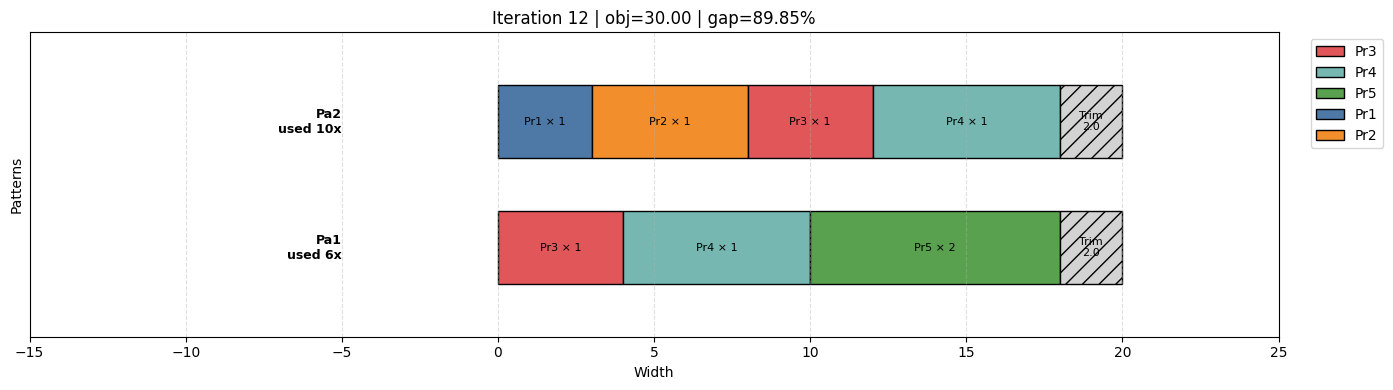

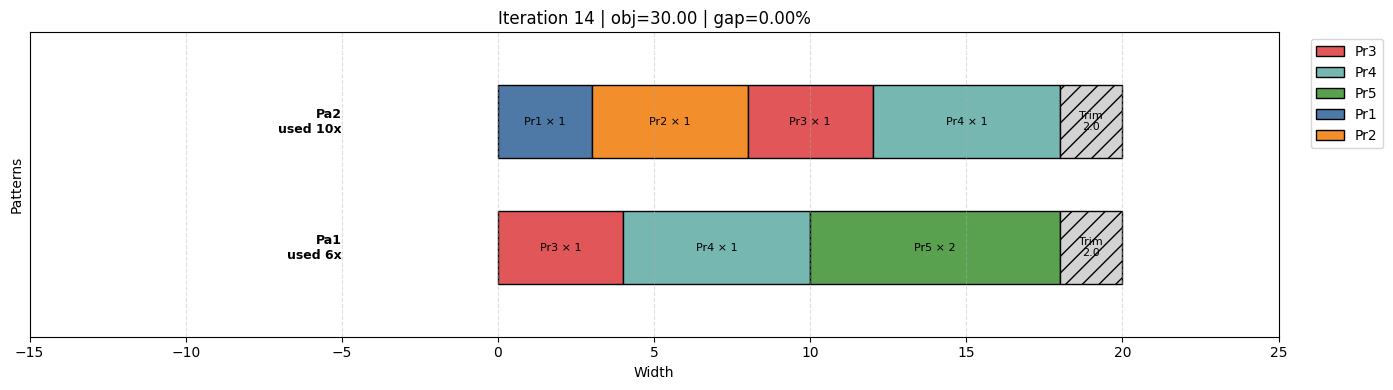

In [12]:
# Plot the cutting patterns of each recorded solution
for row in primal_log:
    plot_patterns(row["sol"], n, m, f"Iteration {row['iter']} | obj={row['obj']:.2f} | gap={row['gap (%)']:.2f}%")